<a href="https://colab.research.google.com/github/nabillahumi/S5-Mesin_Learning/blob/main/Jobsheet%2011%20PBL/Praktikum%203%20(JS11)%20PBL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Langkah 1 - Import Library & Buat Fungsi Plotting

In [2]:
# Import library yang dibutuhkan
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

# Fungsi untuk menampilkan fitting dan decision boundary SVM
def plot_svc_decision_function(model, ax=None, plot_support=True):
    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # Buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y_grid = np.linspace(ylim[0], ylim[1], 30)
    Y, X_grid = np.meshgrid(y_grid, x)
    xy = np.vstack([X_grid.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X_grid.shape)

    # Plot batas dan margin
    ax.contour(X_grid, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    # Plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none', edgecolors='k')
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

#Langkah 2 - Load Dataset & Preprocessing (Data Overlapping)

In [3]:
# Memuat dataset cafes.csv dan reviews.csv
cafes_df = pd.read_csv('cafes.csv')
reviews_df = pd.read_csv('reviews.csv')

# Agregasi data review per cafe_id
reviews_agg = reviews_df.groupby('cafe_id').agg(
    avg_review_rating=('rating', 'mean'),
    total_scraped_reviews=('review_id', 'count')
).reset_index()

# Menggabungkan dengan cafes.csv
merged_df = pd.merge(cafes_df, reviews_agg, on='cafe_id', how='inner')
merged_df = merged_df.dropna(subset=['rating', 'avg_review_rating'])

# Menyiapkan Fitur (X) dan Label (y)
# Menggunakan rating kafe dan avg_review_rating yang memiliki area irisan (overlapping)
X = merged_df[['rating', 'avg_review_rating']].values

# Standardisasi fitur
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Membuat label biner dengan titik potong median agar terjadi overlapping data
median_val = np.median(merged_df['avg_review_rating'])
y = (merged_df['avg_review_rating'] >= median_val).astype(int)

print("Jumlah data:", X.shape)
print("Distribusi kelas y:", np.bincount(y))

Jumlah data: (94, 2)
Distribusi kelas y: [44 50]


#Langkah 3 - Analisis Dampak Tuning Parameter C pada Data Overlapping

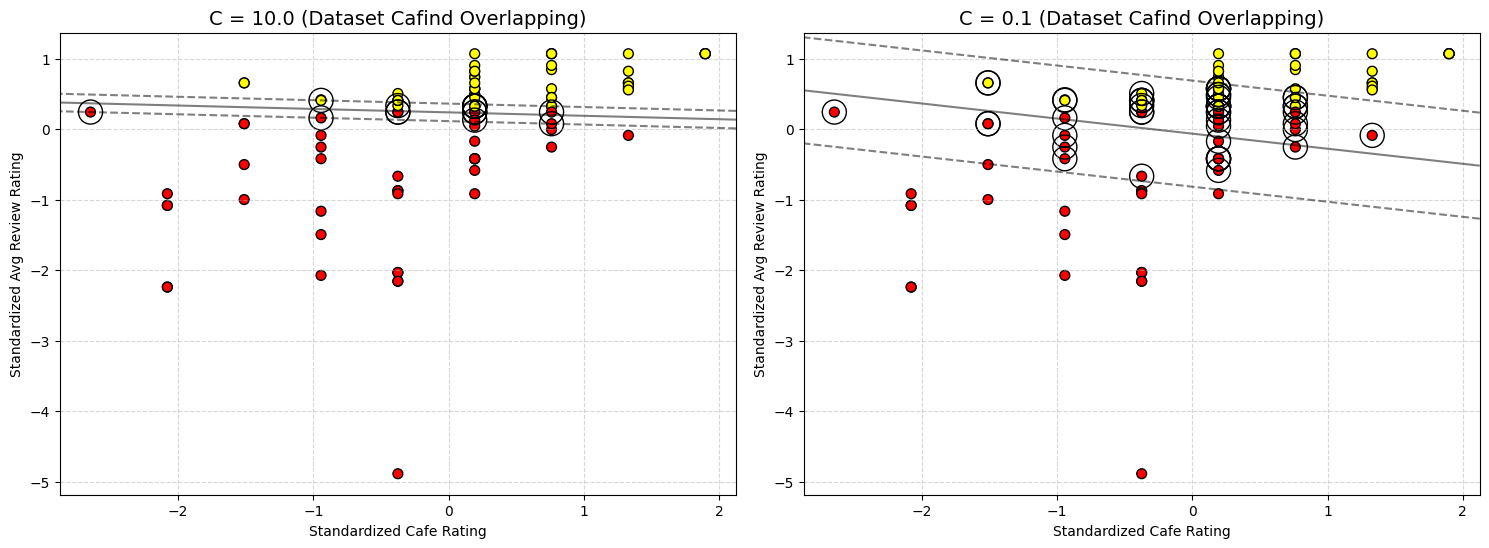

In [4]:
# Membuat plot perbandingan dengan 2 nilai C yang berbeda
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)

# Daftar nilai C yang akan diuji
c_values = [10.0, 0.1]

for axi, C in zip(ax, c_values):
    # Melatih model SVM dengan kernel linier dan parameter C tertentu
    model = SVC(kernel='linear', C=C).fit(X_scaled, y)

    # Plot sebaran data
    axi.scatter(X_scaled[:, 0], X_scaled[:, 1], c=y, s=50, cmap='autumn', edgecolors='k')

    # Panggil fungsi plot decision boundary & margin
    plot_svc_decision_function(model, axi)

    # Judul subplot berdasarkan nilai C
    axi.set_title('C = {0:.1f} (Dataset Cafind Overlapping)'.format(C), size=14)
    axi.set_xlabel('Standardized Cafe Rating')
    axi.set_ylabel('Standardized Avg Review Rating')
    axi.grid(True, linestyle='--', alpha=0.5)

plt.show()